# Figures 7 and S10: Spot Propierties. 

The workflow is organized as:

1. User settings
2. Load and audit data
3. All box-and-whisker plots
4. All particle distributions
5. Particles larger than the selected size threshold

## 1. User settings

In [7]:
from pathlib import Path

# ======================== START USER SETTINGS ========================

# Input and output locations
INPUT_ROOT = Path("/Volumes/LaCie/UTag_paper_data/ACF")
FIGURES_FOLDER_NAME = "figures"
DATA_FOLDER_NAME = "raw_data"

# Conditions: folder, displayed label, CSV label, and distribution color
CONDITIONS = {
    "utag": {
        "folder": "UTag_ACF",
        "label": "UTag",
        "export_label": "UTag",
        "color": "#0173B2",
    },
    "utag_c_free": {
        "folder": "UTag_CF_ACF",
        "label": r"UTag($\Delta$Cys)",
        "export_label": "UTag_DeltaCys",
        "color": "#DE8F05",
    },
    "suntag": {
        "folder": "SunTag_ACF",
        "label": "SunTag",
        "export_label": "SunTag",
        "color": "#029E73",
    },
    "alfatag": {
        "folder": "AlfaTag_ACF",
        "label": "ALFA-tag",
        "export_label": "ALFA_tag",
        "color": "#CC78BC",
    },
}

# Analysis settings
CHANNEL_INDEX = 0
SELECTED_FRAME = None
USE_METADATA_PIXEL_SIZE = False
FIXED_PIXEL_XY_UM = 0.12989318982387477
MINIMUM_SNR = 0.0
SPOT_SIZE_THRESHOLD_UM = 0.5

# Each box-and-whisker figure: output name, CSV name, label, and y-axis limits.
# Use None for automatic y-axis limits.
WHISKER_FIGURES = {
    "spots_per_cell": {
        "figure_name": "figure_spots_per_cell",
        "data_name": "data_spots_per_cell.csv",
        "y_label": "Trajectories per cell",
        "y_limits": None,
    },
    "spots_per_cell_filtered": {
        "figure_name": "figure_spots_per_cell_filtered",
        "data_name": "data_spots_per_cell_filtered.csv",
        "y_label": r"Trajectories per cell ($\leq {threshold_um:g}\ \mu$m)",
        "y_limits": None,
    },
    "spot_intensity": {
        "figure_name": "figure_spot_intensity",
        "data_name": "data_spot_intensity.csv",
        "y_label": "Intensity (a.u.)",
        "y_limits": (0, 4500),
    },
    "snr": {
        "figure_name": "figure_snr",
        "data_name": "data_snr.csv",
        "y_label": "SNR",
        "y_limits": (1, 5),
    },
    "spot_size": {
        "figure_name": "figure_spot_size",
        "data_name": "data_spot_size.csv",
        "y_label": r"Spot Size ($\mu$m)",
        "y_limits": (0.25, 0.55),
    },
    "spot_intensity_filtered": {
        "figure_name": "figure_spot_intensity_filtered",
        "data_name": "data_spot_intensity_filtered.csv",
        "y_label": r"Intensity ($\leq {threshold_um:g}\ \mu$m, a.u.)",
        "y_limits": (0, 4500),
    },
    "snr_filtered": {
        "figure_name": "figure_snr_filtered",
        "data_name": "data_snr_filtered.csv",
        "y_label": r"SNR ($\leq {threshold_um:g}\ \mu$m)",
        "y_limits": (1, 5),
    },
    "spot_size_filtered": {
        "figure_name": "figure_spot_size_filtered",
        "data_name": "data_spot_size_filtered.csv",
        "y_label": r"Spot Size ($\leq {threshold_um:g}\ \mu$m)",
        "y_limits": (0.25, 0.45),
    },
}

# Each distribution: figure name, observation CSV, KDE CSV, label, and limits.
DISTRIBUTION_FIGURES = {
    "intensity_distribution": {
        "figure_name": "figure_spot_intensity_distribution",
        "data_name": "data_spot_intensity_distribution.csv",
        "kde_data_name": "data_spot_intensity_distribution_kde.csv",
        "x_label": "Spot Intensity (a.u.)",
        "x_limits": (-10, 8000),
    },
    "size_distribution": {
        "figure_name": "figure_spot_size_distribution",
        "data_name": "data_spot_size_distribution.csv",
        "kde_data_name": "data_spot_size_distribution_kde.csv",
        "x_label": r"Spot Size ($\mu$m)",
        "x_limits": (0.18, 0.9),
        "show_inset": True,
        "inset_xlim": (0.5, 0.9),
        "inset_bounds": (0.43, 0.46, 0.50, 0.34),
        "show_density_fill": False,
        "legend_inside": True,
        "show_tail_background": False,
        "show_inset_fill": False,
        "show_inset_title": False,
        "inset_tick_size": 18.5,
    },
    "intensity_distribution_filtered": {
        "figure_name": "figure_spot_intensity_distribution_filtered",
        "data_name": "data_spot_intensity_distribution_filtered.csv",
        "kde_data_name": "data_spot_intensity_distribution_kde_filtered.csv",
        "x_label": r"Spot Intensity ($\leq {threshold_um:g}\ \mu$m, a.u.)",
        "x_limits": (-10, 8000),
    },
    "size_distribution_filtered": {
        "figure_name": "figure_spot_size_distribution_filtered",
        "data_name": "data_spot_size_distribution_filtered.csv",
        "kde_data_name": "data_spot_size_distribution_kde_filtered.csv",
        "x_label": r"Spot Size ($\leq {threshold_um:g}\ \mu$m)",
        "x_limits": (0.18, 0.55),
        "show_inset": False,
        "show_density_fill": False,
        "legend_inside": True,
    },
}

# Final analysis: percentage of particles larger than the threshold.
LARGE_SPOT_FIGURE = {
    "figure_name": "figure_spots_larger_than_threshold",
    "data_name": "data_spots_larger_than_threshold.csv",
    "y_label": r"Spots > {threshold_um:g} $\mu$m (% per cell)",
    "y_limits": (-1, 30),
}
PAIRWISE_STATISTICS_DATA_NAME = "data_pairwise_statistics.csv"

# Shared plot appearance
FONT_FAMILY = "Arial"
WHISKER_STYLE = {
    "figsize": (6.5, 4.5),
    "tick_size": 18,
    "show_stats": True,
    "save_formats": ("png", "svg"),
    "save_dpi": 600,
}
DISTRIBUTION_STYLE = {
    "mode": 1,  # one mean value per tracked particle
    "figsize": (6.6, 5.1),
    "tick_size": 19,
    "save_formats": ("png", "svg"),
    "save_dpi": 600,
}
SHOW_SUMMARY_TABLES = True

# ========================= END USER SETTINGS =========================

## 2. Setup and load data


In [8]:
import sys
import warnings

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


def find_project_dir(start_path):
    """Return the nearest parent directory containing the Git repository."""
    start_path = Path(start_path).resolve()
    for candidate in (start_path, *start_path.parents):
        if (candidate / ".git").exists():
            return candidate
    raise FileNotFoundError(
        f"Could not locate the project root from {start_path}."
    )


PROJECT_DIR = find_project_dir(Path.cwd())
NOTEBOOK_DIR = (
    PROJECT_DIR / "notebooks" / "Figure_7_and_S10_spot_distributions"
)
FIGURES_DIR = NOTEBOOK_DIR / FIGURES_FOLDER_NAME
RAW_DATA_DIR = NOTEBOOK_DIR / DATA_FOLDER_NAME
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from processing_spot_size import (
    build_audit_dataframe,
    load_tracking_records,
    run_distribution_analyses,
    run_large_spot_analysis,
    run_whisker_analyses,
    save_pairwise_statistics,
)

CONDITION_KEYS = tuple(CONDITIONS)
DATASET_FOLDERS = {
    key: settings["folder"] for key, settings in CONDITIONS.items()
}
CONDITION_LABELS = {
    key: settings["label"] for key, settings in CONDITIONS.items()
}
CONDITION_EXPORT_LABELS = {
    key: settings["export_label"] for key, settings in CONDITIONS.items()
}
CONDITION_COLORS = {
    key: settings["color"] for key, settings in CONDITIONS.items()
}

%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("ticks")
plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.linewidth": 2.0,
    "axes.labelsize": 22,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 15,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})

print(f"Input root: {INPUT_ROOT}")
print(f"Figures: {FIGURES_DIR}")
print(f"Data: {RAW_DATA_DIR}")

Input root: /Volumes/LaCie/UTag_paper_data/ACF
Figures: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures
Data: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data


In [9]:
TRACKING_RECORDS = load_tracking_records(
    INPUT_ROOT,
    DATASET_FOLDERS,
    use_metadata_pixel_size=USE_METADATA_PIXEL_SIZE,
    fixed_pixel_xy_um=FIXED_PIXEL_XY_UM,
)
audit_df = build_audit_dataframe(TRACKING_RECORDS, CONDITION_LABELS)
display(audit_df)

,condition,cells/files,dataframe rows,unique particles,pixel sizes (um/px)
0,UTag,19,139658,1257,[0.129893189824]
1,UTag($\Delta$Cys),14,94722,1011,[0.129893189824]
2,SunTag,16,65280,682,[0.129893189824]
3,ALFA-tag,11,76489,652,[0.129893189824]


## 3. Box-and-whisker plots

This cell creates all eight whisker plots in the order listed in
`WHISKER_FIGURES`.

- Unfiltered spot counts are unique tracked particles per cell.
- Filtered counts include particles whose mean size is ≤ the threshold.
- Filtered intensity, SNR, and size use one mean per eligible particle before
  calculating the cell mean.
- Every black point is one cell; whiskers span the 5th–95th percentiles.

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spots_per_cell.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spots_per_cell.svg


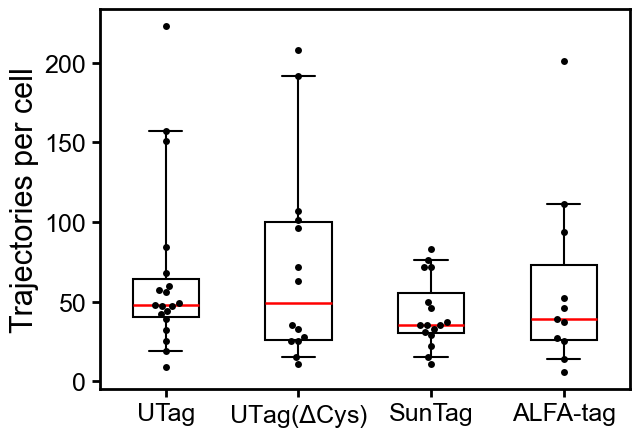

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spots_per_cell.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spots_per_cell_filtered.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spots_per_cell_filtered.svg


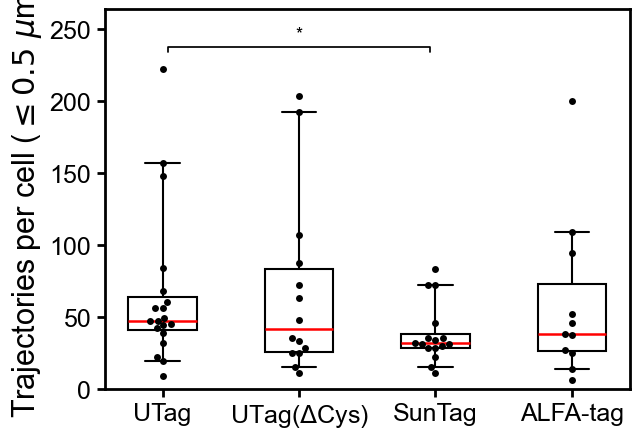

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spots_per_cell_filtered.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_intensity.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_intensity.svg


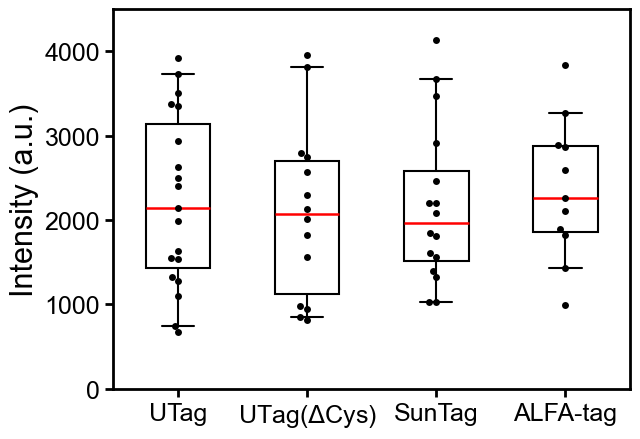

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_intensity.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_snr.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_snr.svg


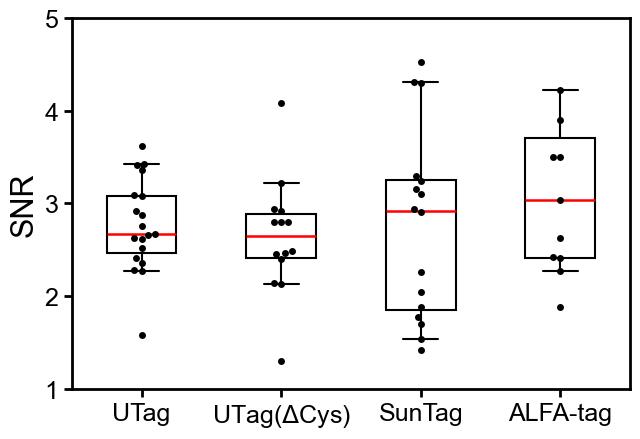

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_snr.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_size.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_size.svg


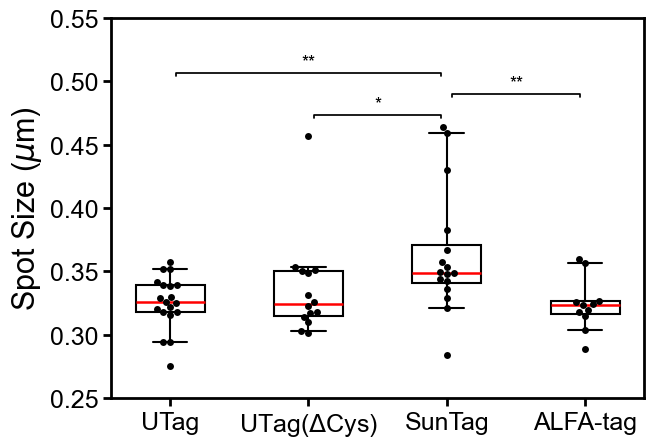

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_size.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_intensity_filtered.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_intensity_filtered.svg


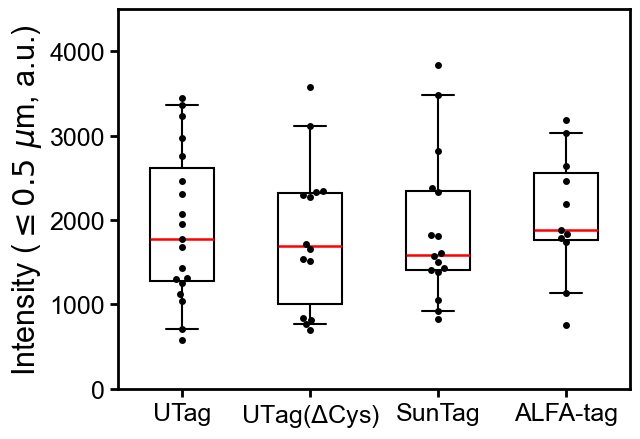

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_intensity_filtered.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_snr_filtered.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_snr_filtered.svg


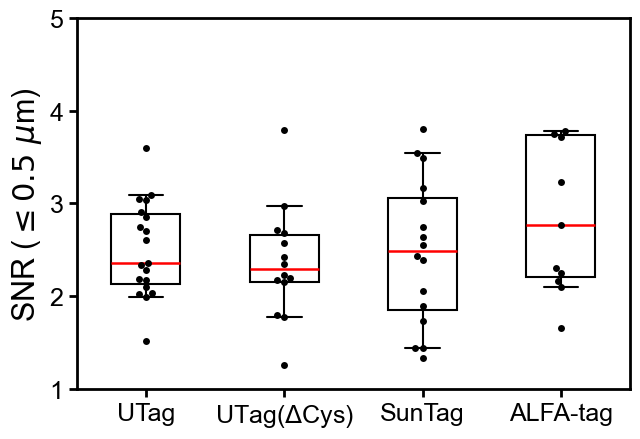

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_snr_filtered.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_size_filtered.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_size_filtered.svg


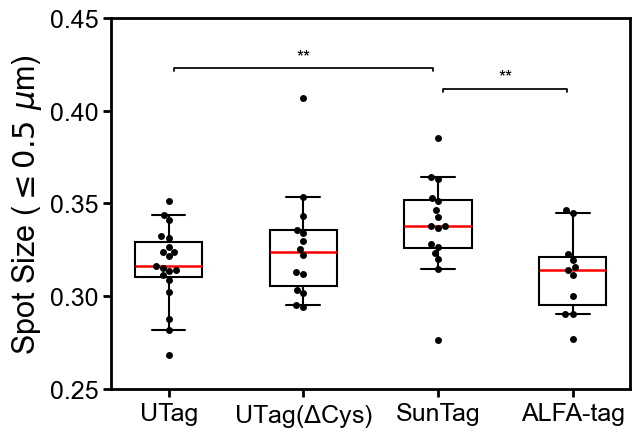

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_size_filtered.csv
spots_per_cell


,Condition,count,mean,std,median
0,UTag,19,66.157895,53.809606,48.0
1,UTag($\Delta$Cys),14,72.214286,63.143522,49.0
2,SunTag,16,42.625000,22.126530,35.0
3,ALFA-tag,11,59.272727,56.752253,39.0


spots_per_cell_filtered


,Condition,count,mean,std,median
0,UTag,19,65.578947,53.589298,47.0
1,UTag($\Delta$Cys),14,67.428571,61.762217,41.5
2,SunTag,16,37.812500,20.569293,31.5
3,ALFA-tag,11,58.909091,56.358592,38.0


spot_intensity


,Condition,count,mean,std,median
0,UTag,19,2227.160910,1027.091773,2141.971796
1,UTag($\Delta$Cys),14,2090.200908,1027.900608,2067.337403
2,SunTag,16,2170.291675,942.109994,1962.955056
3,ALFA-tag,11,2360.443132,830.589097,2262.753734


... (6 outputs left out)

snr_filtered


,Condition,count,mean,std,median
0,UTag,19,2.503179,0.510790,2.360374
1,UTag($\Delta$Cys),14,2.361515,0.602135,2.289023
2,SunTag,16,2.479794,0.789589,2.490971
3,ALFA-tag,11,3.089169,1.292269,2.765598


spot_size_filtered


,Condition,count,mean,std,median
0,UTag,19,0.316598,0.021016,0.316033
1,UTag($\Delta$Cys),14,0.326483,0.029301,0.323938
2,SunTag,16,0.337935,0.024705,0.337843
3,ALFA-tag,11,0.312102,0.021876,0.314283


In [10]:
WHISKER_RESULTS, PAIRWISE_STATISTICS = run_whisker_analyses(
    tracking_records=TRACKING_RECORDS,
    condition_keys=CONDITION_KEYS,
    display_labels=CONDITION_LABELS,
    export_labels=CONDITION_EXPORT_LABELS,
    figures=WHISKER_FIGURES,
    figures_dir=FIGURES_DIR,
    raw_data_dir=RAW_DATA_DIR,
    channel_index=CHANNEL_INDEX,
    selected_frame=SELECTED_FRAME,
    threshold_um=SPOT_SIZE_THRESHOLD_UM,
    minimum_snr=MINIMUM_SNR,
    style=WHISKER_STYLE,
)

if SHOW_SUMMARY_TABLES:
    for key in WHISKER_FIGURES:
        print(key)
        display(WHISKER_RESULTS[key]["summary"])

## 4. Particle distributions

These plots use one mean value per tracked particle. The filtered distributions
retain particles according to their mean spot size.

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_intensity_distribution.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_intensity_distribution.svg


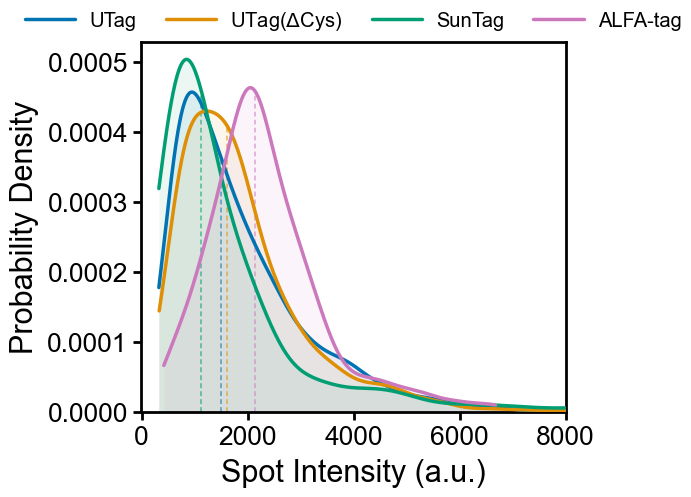

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_intensity_distribution.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_intensity_distribution_kde.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_size_distribution.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_size_distribution.svg


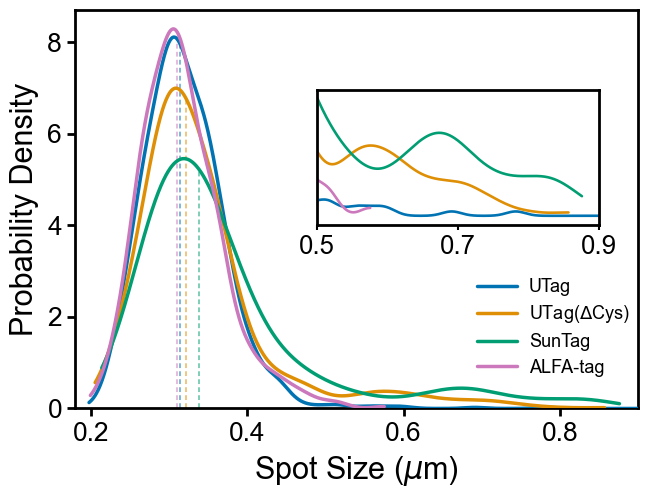

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_size_distribution.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_size_distribution_kde.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_intensity_distribution_filtered.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_intensity_distribution_filtered.svg


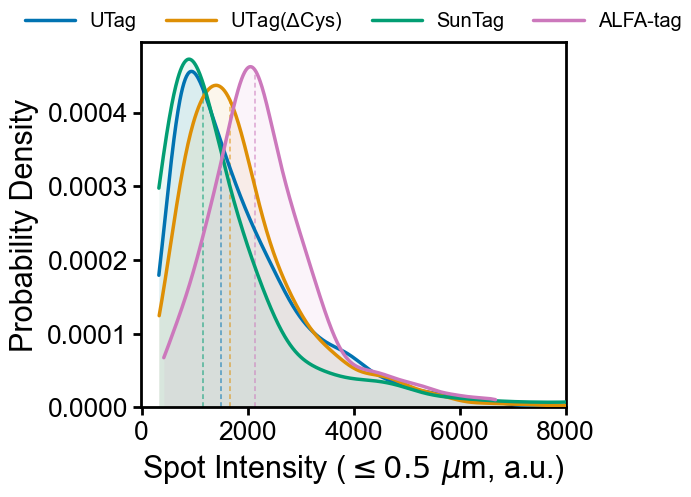

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_intensity_distribution_filtered.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_intensity_distribution_kde_filtered.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_size_distribution_filtered.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spot_size_distribution_filtered.svg


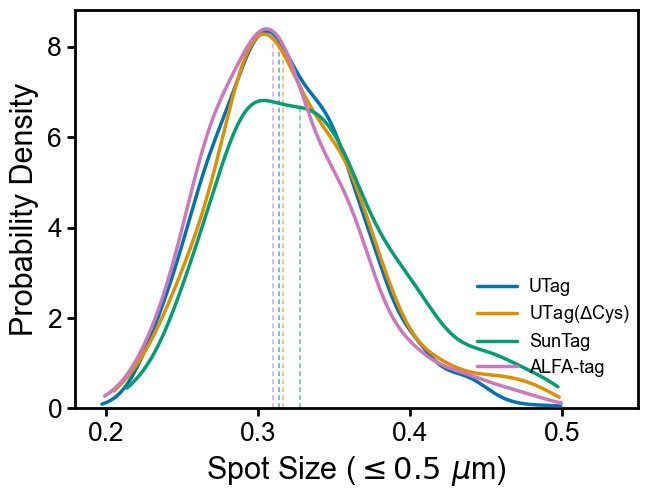

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_size_distribution_filtered.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spot_size_distribution_kde_filtered.csv


In [11]:
DISTRIBUTION_RESULTS = run_distribution_analyses(
    tracking_records=TRACKING_RECORDS,
    condition_keys=CONDITION_KEYS,
    display_labels=CONDITION_LABELS,
    export_labels=CONDITION_EXPORT_LABELS,
    colors=CONDITION_COLORS,
    figures=DISTRIBUTION_FIGURES,
    figures_dir=FIGURES_DIR,
    raw_data_dir=RAW_DATA_DIR,
    channel_index=CHANNEL_INDEX,
    threshold_um=SPOT_SIZE_THRESHOLD_UM,
    minimum_snr=MINIMUM_SNR,
    style=DISTRIBUTION_STYLE,
)

## 5. Particles larger than the size threshold

This final analysis classifies each particle using its mean size across valid
frames. Each plotted point is one cell:

$$100 \times \frac{n_{>\mathrm{threshold}}}{n_{\mathrm{eligible}}}.$$

Plot annotations use raw Mann–Whitney p-values for compatibility. The combined
statistics CSV contains both raw and Holm-adjusted p-values.

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_spots_larger_than_threshold.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spots_larger_than_threshold.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/figures/figure_spots_larger_than_threshold.svg


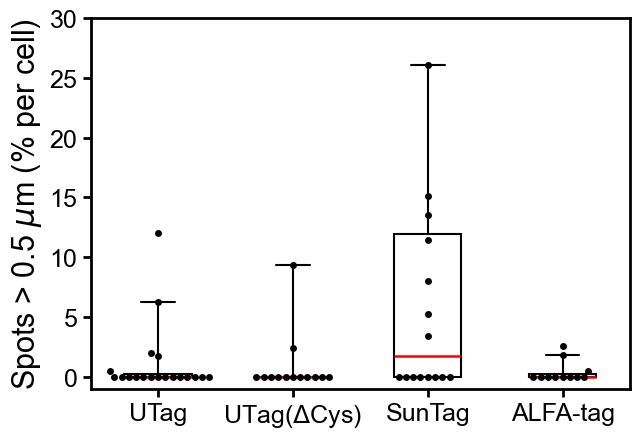

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S10_spot_distributions/raw_data/data_pairwise_statistics.csv


,condition,cells,spots_above_threshold,total_valid_spots,mean_cell_percentage,median_cell_percentage,pooled_percentage_above_threshold
0,UTag,19,11,1257,1.181030,0.000000,0.875099
1,UTag($\Delta$Cys),14,67,1011,4.589578,0.000000,6.627102
2,SunTag,16,77,682,8.826583,1.724138,11.290323
3,ALFA-tag,11,4,652,0.442129,0.000000,0.613497


,plot,condition_1,condition_2,test,alternative,p_value_raw,significance_raw,p_value_holm,significance_holm,annotation_displayed,annotation_basis
0,figure_spots_per_cell,UTag,UTag_DeltaCys,Mann-Whitney U,two-sided,0.956408,ns,1.000000,ns,False,raw p-value
1,figure_spots_per_cell,UTag,SunTag,Mann-Whitney U,two-sided,0.149575,ns,0.897450,ns,False,raw p-value
2,figure_spots_per_cell,UTag,ALFA_tag,Mann-Whitney U,two-sided,0.365960,ns,1.000000,ns,False,raw p-value
3,figure_spots_per_cell,UTag_DeltaCys,SunTag,Mann-Whitney U,two-sided,0.491899,ns,1.000000,ns,False,raw p-value
4,figure_spots_per_cell,UTag_DeltaCys,ALFA_tag,Mann-Whitney U,two-sided,0.721754,ns,1.000000,ns,False,raw p-value
5,figure_spots_per_cell,SunTag,ALFA_tag,Mann-Whitney U,two-sided,0.674564,ns,1.000000,ns,False,raw p-value
6,figure_spots_per_cell_filtered,UTag,UTag_DeltaCys,Mann-Whitney U,two-sided,0.812790,ns,1.000000,ns,False,raw p-value
7,figure_spots_per_cell_filtered,UTag,SunTag,Mann-Whitney U,two-sided,0.035389,*,0.212337,ns,True,raw p-value
8,figure_spots_per_cell_filtered,UTag,ALFA_tag,Mann-Whitney U,two-sided,0.389282,ns,1.000000,ns,False,raw p-value
9,figure_spots_per_cell_filtered,UTag_DeltaCys,SunTag,Mann-Whitney U,two-sided,0.327752,ns,1.000000,ns,False,raw p-value


Y-axis scaled to 30% for clarity; two cells exceeding 30% are marked at top (UTag(ΔCys): 52.5%, SunTag: 58.3%).


In [14]:
LARGE_SPOT_RESULT = run_large_spot_analysis(
    tracking_records=TRACKING_RECORDS,
    condition_keys=CONDITION_KEYS,
    display_labels=CONDITION_LABELS,
    export_labels=CONDITION_EXPORT_LABELS,
    figure=LARGE_SPOT_FIGURE,
    figures_dir=FIGURES_DIR,
    raw_data_dir=RAW_DATA_DIR,
    channel_index=CHANNEL_INDEX,
    threshold_um=SPOT_SIZE_THRESHOLD_UM,
    minimum_snr=MINIMUM_SNR,
    style=WHISKER_STYLE,
)
PAIRWISE_STATISTICS["larger_than_threshold"] = (
    LARGE_SPOT_RESULT["statistics"]
)

pairwise_statistics = save_pairwise_statistics(
    PAIRWISE_STATISTICS,
    RAW_DATA_DIR / PAIRWISE_STATISTICS_DATA_NAME,
)

if SHOW_SUMMARY_TABLES:
    display(LARGE_SPOT_RESULT["condition_summary"])
    display(pairwise_statistics)

# print that the 2 outliers were removed to improve
print( "Y-axis scaled to 30% for clarity; two cells exceeding 30% are marked at top (UTag(ΔCys): 52.5%, SunTag: 58.3%).")



